<a href="https://colab.research.google.com/github/QuantLet/CBDC/blob/main/CBDC%20vs.%20Stablecoin/Stablecoins%20depegging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import math

# --- Stablecoin: Probabilistic Finality ---
# On Ethereum, a transaction is "final" after ~12 confirmations
# Probability of reversal decays exponentially with block depth

def reversal_probability(confirmations, attacker_hashrate=0.25):
    """
    Probability of successful double-spend attack
    Given attacker controls 'attacker_hashrate' of total hash power
    """
    q = attacker_hashrate  # Attacker share
    p = 1 - q              # Honest share

    if q >= 0.5:
        return 1.0  # Attacker always wins

    # Nakamoto probability: P(reversal | z confirmations)
    lam = confirmations * (q / p)
    prob = 1.0 - np.sum([
        np.exp(-lam) * (lam ** k) / math.factorial(k)
        for k in range(confirmations)
    ])
    return prob

# Compute for different confirmation depths
print("Stablecoin (Ethereum) — Probabilistic Finality:")
print("Confirmations | Reversal Probability")
for z in [1, 6, 12, 20, 50]:
    p_rev = reversal_probability(z, attacker_hashrate=0.30)
    print(f"  {z:2d}          | {p_rev:.2e}")

# --- CBDC: Legal Finality ---
print("\nCBDC — Legal Finality:")
print("  Reversal probability: 0.0000 (by legal statute)")
print("  Settlement time:      Instant (central ledger update)")
print("  Counterparty risk:    None (sovereign guarantee)")

# --- Practical Comparison ---
print("\n--- Practical Settlement Comparison ---")
print(f"Stablecoin 'safe' finality: ~12 confirmations ≈ 3 minutes")
print(f"CBDC finality:              1 confirmation  ≈ 0 seconds")
print(f"\nFor a $1M wholesale payment:")
print(f"  Stablecoin risk window: 3 min × volatility exposure")
print(f"  CBDC risk window:       0 (legally settled)")

Stablecoin (Ethereum) — Probabilistic Finality:
Confirmations | Reversal Probability
   1          | 3.49e-01
   6          | 4.70e-02
  12          | 6.74e-03
  20          | 5.92e-04
  50          | 9.84e-08

CBDC — Legal Finality:
  Reversal probability: 0.0000 (by legal statute)
  Settlement time:      Instant (central ledger update)
  Counterparty risk:    None (sovereign guarantee)

--- Practical Settlement Comparison ---
Stablecoin 'safe' finality: ~12 confirmations ≈ 3 minutes
CBDC finality:              1 confirmation  ≈ 0 seconds

For a $1M wholesale payment:
  Stablecoin risk window: 3 min × volatility exposure
  CBDC risk window:       0 (legally settled)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import os
import glob
from datetime import datetime

In [2]:
drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/stablecoins_data"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
if not os.path.exists(data_path):
    raise FileNotFoundError(f"path {data_path} not esist")

# 4. 读取所有CSV文件
csv_files = glob.glob(os.path.join(data_path, "*.csv"))
print(f"find {len(csv_files)} csv files")

if len(csv_files) == 0:
    raise ValueError("find 0 file")

find 359 csv files


In [5]:
#### merging

all_data = []

for file in csv_files:
    coin_name = os.path.basename(file).replace('.csv', '')
    try:
        df = pd.read_csv(file)

        df.columns = df.columns.str.strip().str.lower()  # all lower

        # check columns
        required_cols = ['date', 'prices', 'market_caps', 'total_volumes']
        if not all(col in df.columns for col in required_cols):
            print(f"警告：文件 {coin_name} 缺少必要列，跳过。")
            continue

        # mark coinname
        df['coin'] = coin_name

        # check date
        date_series = df['date'].astype(str)
        df['date'] = pd.to_datetime(date_series, format='%m/%d/%Y', errors='coerce')
        if df['date'].isna().all():
            df['date'] = pd.to_datetime(date_series, format='%Y%m%d', errors='coerce')
        if df['date'].isna().all():
            df['date'] = pd.to_datetime(date_series, format='%Y-%m-%d', errors='coerce')
        if df['date'].isna().any():
            print(f"file {coin_name} contains date?, drop")
            df = df.dropna(subset=['date'])

        # numeric
        for col in ['prices', 'market_caps', 'total_volumes']:
            df[col] = pd.to_numeric(df[col], errors='coerce')

        # drop NA
        df = df.dropna(subset=['prices', 'market_caps', 'total_volumes'], how='all')

        if len(df) == 0:
            print(f"file {coin_name} numeric NA, drop")
            continue

        all_data.append(df)
        print(f"read {coin_name}，rows {len(df)}")
    except Exception as e:
        print(f"error in reading {file} : {e}")

if len(all_data) == 0:
    raise ValueError("cant read data, file problem。")

# merge all
df_all = pd.concat(all_data, ignore_index=True)



read tether，rows 455
read usd-coin，rows 455
read usds，rows 455
read usd1-wlfi，rows 416
read dai，rows 455
read usdd，rows 455
read ethena-usde，rows 455
read ondo-us-dollar-yield，rows 455
read paypal-usd，rows 455
read ripple-usd，rows 455
read global-dollar，rows 455
read bfusd，rows 291
read united-stables，rows 165
read usdtb，rows 455
read falcon-finance，rows 455
read usual-usd，rows 455
read apxusd，rows 91
read a7a5，rows 349
read ylds，rows 145
read true-usd，rows 455
read gho，rows 455
read usx，rows 247
read euro-coin，rows 455
read polymarket-usd，rows 34
read frax，rows 455
read binance-peg-busd，rows 455
read first-digital-usd，rows 455
read satoshi-stablecoin，rows 455
read megausd，rows 116
read crvusd，rows 455
read royal-dollar，rows 83
read usa，rows 125
read gusd，rows 277
read usda-2，rows 410
read saturn-dollar，rows 54
read ibc-bridged-usdc，rows 455
read agora-dollar，rows 455
read nusd-2，rows 204
read frax-usd，rows 455
read stasis-eurs，rows 455
read societe-generale-forge-eurcv，rows 423
read a

In [6]:
# clean data
# order by date
df_all = df_all.sort_values(['coin', 'date']).reset_index(drop=True)

# price deviation
df_all['deviation'] = (df_all['prices'] - 1) * 100  # eg 1.05 -> +5%

# daily return
df_all['return'] = df_all.groupby('coin')['prices'].pct_change() * 100  # precentage

# 7. descriptive
print("\n=== data overview ===")
print(f"Observation: {len(df_all)}")
print(f"unique coins: {df_all['coin'].nunique()}")
print(f"date: {df_all['date'].min()} 至 {df_all['date'].max()}")
print("\ndeviation）:")
print(df_all.groupby('coin')['deviation'].describe().round(4))


=== data overview ===
Observation: 122581
unique coins: 359
date: 2025-03-03 00:00:00 至 2026-05-31 00:00:00

deviation）:
                               count     mean      std      min      25%  \
coin                                                                       
a7a5                           349.0 -98.7946   0.2215 -99.9990 -98.7753   
aegis-yusd                     424.0  -0.0763   0.2201  -2.2342  -0.1477   
aexys-dollar                   316.0   1.1485   1.1350  -1.5144   0.2663   
ageur                          455.0  15.4953   2.7126   4.4101  14.8622   
agora-dollar                   455.0  -0.0320   0.0374  -0.1840  -0.0510   
...                              ...      ...      ...      ...      ...   
yuzu-usd                       206.0  -0.0387   0.0873  -0.3145  -0.0832   
zarp-stablecoin                455.0 -94.2925   0.3093 -95.2566 -94.4710   
zasset-zusd                    405.0 -13.7670  11.6647 -61.1982 -19.6351   
zedxion-usdz                   420.0 -16.2

/tmp/ipykernel_1638/820945360.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='coin', y='deviation', data=box_data, palette='Set3', fliersize=2) # outliers as dot


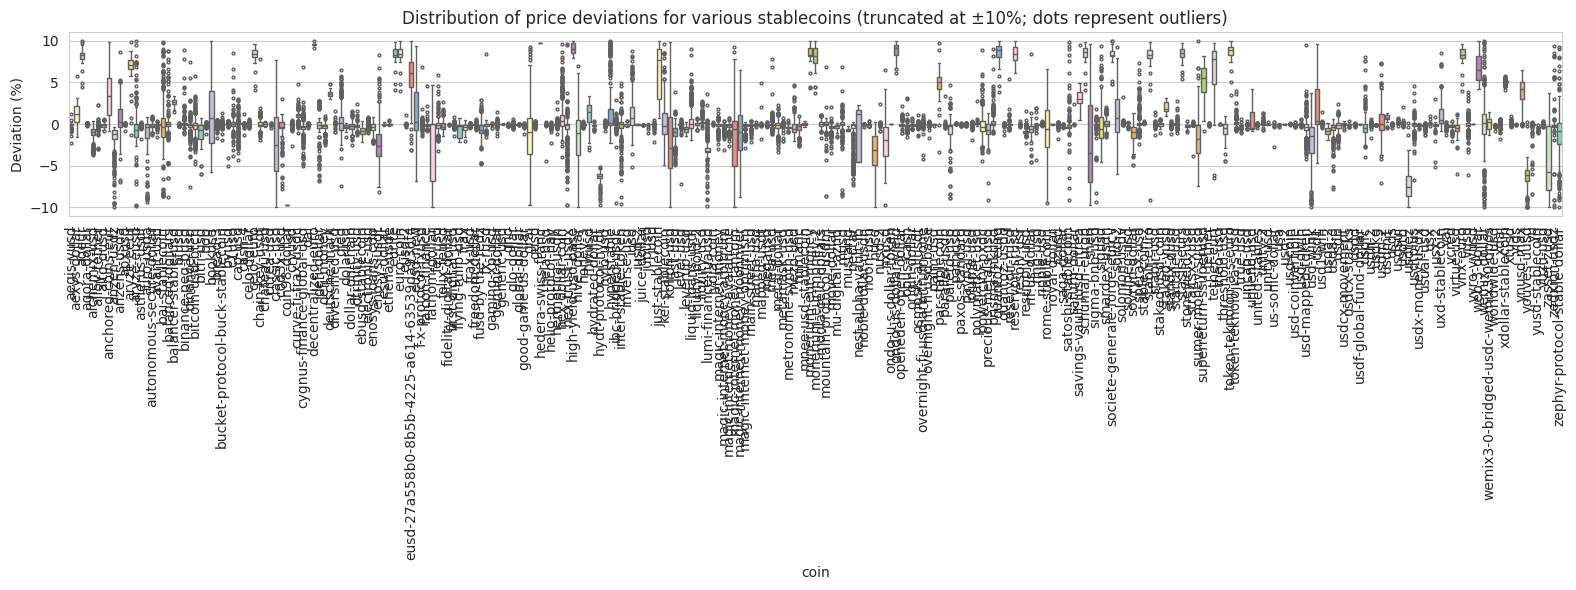

In [7]:
# visual

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ------------------- 1: all sample- box deviation -------------------
plt.figure(figsize=(16, 6))
# show only [-10, 10] to catch main distribution, keep outliers
box_data = df_all[df_all['deviation'].between(-10, 10)]
sns.boxplot(x='coin', y='deviation', data=box_data, palette='Set3', fliersize=2) # outliers as dot
plt.xticks(rotation=90)
plt.title('Distribution of price deviations for various stablecoins (truncated at ±10%; dots represent outliers)')
plt.ylabel('Deviation (%)')#%
plt.tight_layout()
plt.show()

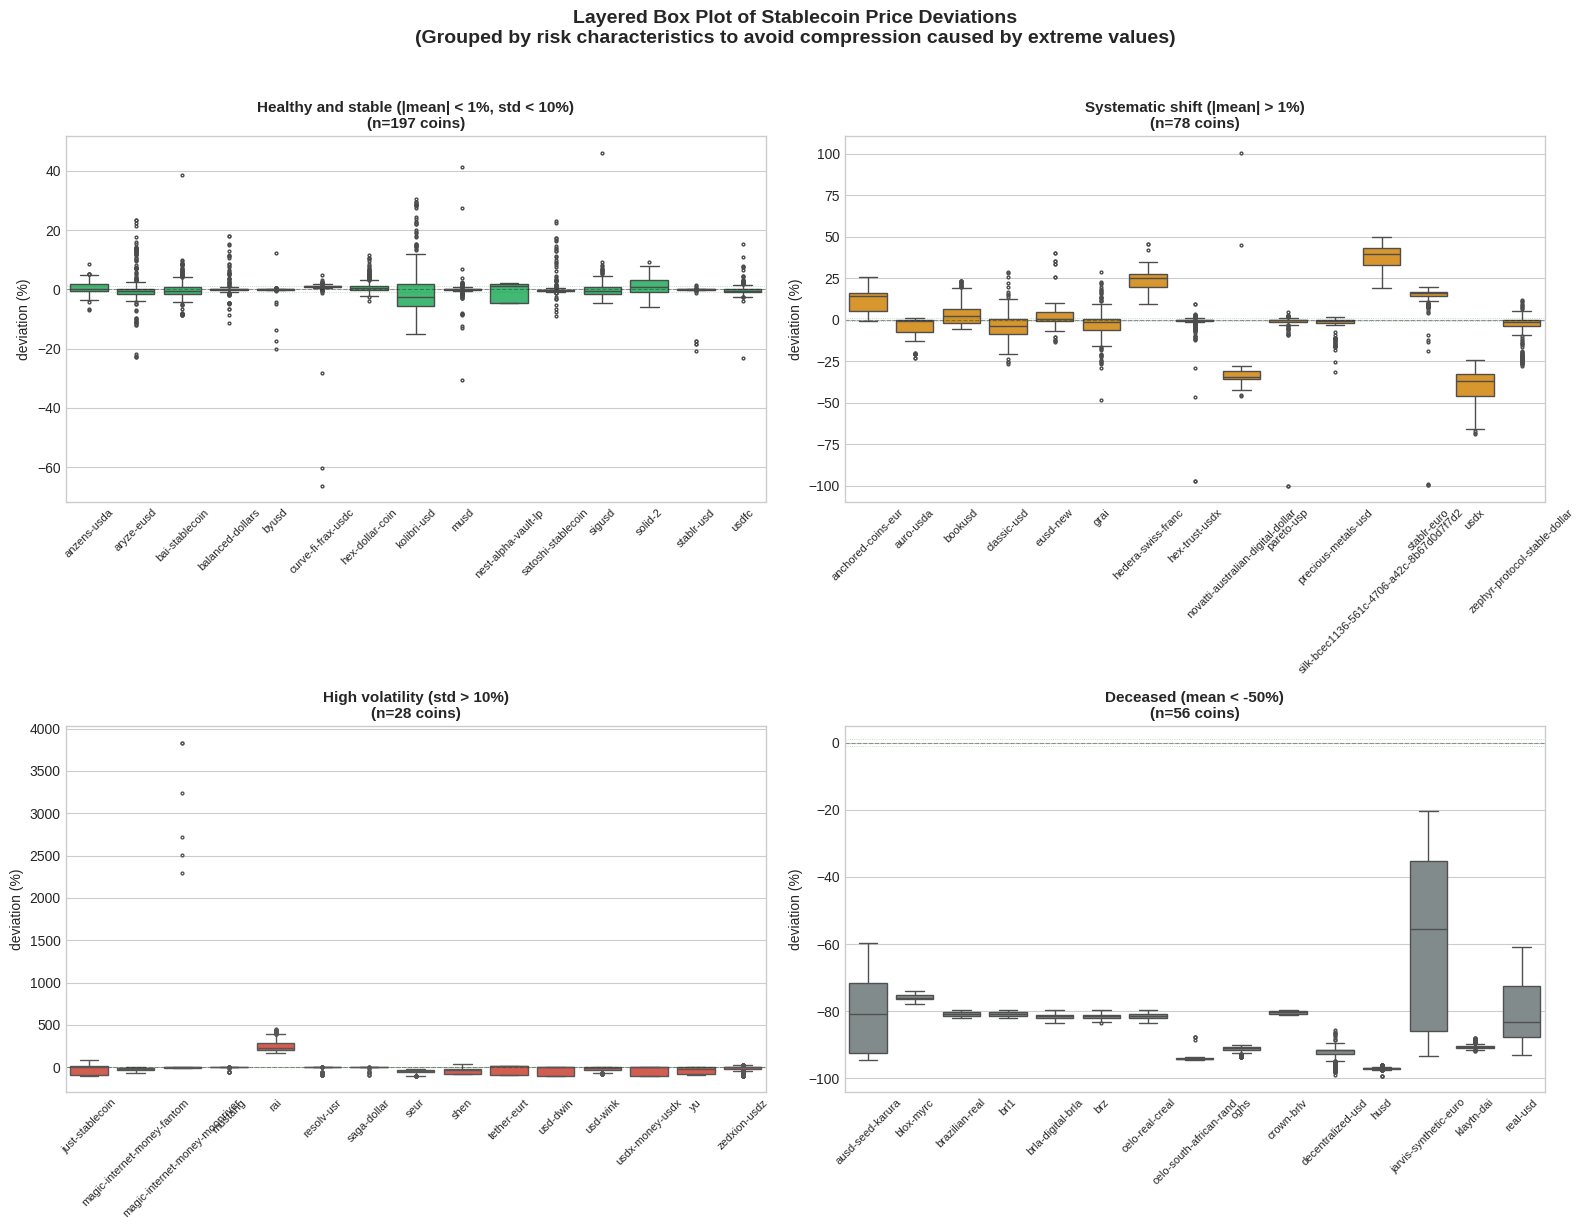

In [31]:
stats = df_all.groupby('coin')['deviation'].agg(['mean', 'std', 'min', 'max', 'count']).reset_index()

# class base on mean and std
def classify_coin(row):
    if row['mean'] < -50:
        return 'Deceased (mean < -50%)'
    elif row['std'] > 10:
        return 'High volatility (std > 10%)'
    elif abs(row['mean']) > 1:
        return 'Systematic shift (|mean| > 1%)'
    else:
        return 'Healthy and stable (|mean| < 1%, std < 10%)'

stats['category'] = stats.apply(classify_coin, axis=1)

# merge
# update to check and delete old category rows to avoid KeyError
if 'category' in df_all.columns:
    df_all = df_all.drop(columns=['category'])
df_all = df_all.merge(stats[['coin', 'category']], on='coin', how='left')

# --- Start of fix for font and directory issues ---
# Install CJK font for matplotlib

import matplotlib.pyplot as plt


# Create output directory if it doesn't exist
import os
output_dir = '/mnt/agents/output'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)
# --- End of fix ---


# style
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_alpha(0)
axes = axes.flatten()


categories = ['Healthy and stable (|mean| < 1%, std < 10%)',
              'Systematic shift (|mean| > 1%)',
              'High volatility (std > 10%)',
              'Deceased (mean < -50%)']

colors = ['#2ecc71', '#f39c12', '#e74c3c', '#7f8c8d']

for idx, (cat, color) in enumerate(zip(categories, colors)):
    ax = axes[idx]
    ax.patch.set_alpha(0)
    subset = df_all[df_all['category'] == cat]

    if len(subset) == 0:
        ax.text(0.5, 0.5, f'no data\n{cat}', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(cat, fontsize=11, fontweight='bold')
        continue

    # present top coins top 15 ordered by std
    top_coins = (subset.groupby('coin')['deviation']
                 .std().sort_values(ascending=False).head(15).index.tolist())

    # if less than 15 show all
    if len(subset['coin'].unique()) <= 15:
        plot_data = subset
    else:
        plot_data = subset[subset['coin'].isin(top_coins)]

    # boxplot
    sns.boxplot(data=plot_data, x='coin', y='deviation', ax=ax, color=color, fliersize=2)

    ax.set_title(f'{cat}\n(n={len(subset["coin"].unique())} coins)',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('deviation (%)', fontsize=10)
    ax.tick_params(axis='x', rotation=45, labelsize=8)

    # add baseline
    ax.axhline(y=0, color='black', linestyle='--', alpha=0.3, linewidth=0.8)
    ax.axhline(y=1, color='green', linestyle=':', alpha=0.3, linewidth=0.6)
    ax.axhline(y=-1, color='green', linestyle=':', alpha=0.3, linewidth=0.6)

plt.suptitle('Layered Box Plot of Stablecoin Price Deviations\n(Grouped by risk characteristics to avoid compression caused by extreme values)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

plt.savefig('/mnt/agents/output/stablecoin_boxplot_layered.png', dpi=300, bbox_inches='tight')
plt.show()

Low‑risk coins selected: ['ondo-u-s-dollar-token', 'usdf-global-fund-dollar', 'ylds', 'usd-2', 'usd-coin', 'global-dollar', 'noble-dollar-usdn', 'iusd-2', 'fidelity-digital-dollar', 'royal-dollar', 'juice-dollar', 'pathusd', 'paypal-usd', 'usds', 'generic-usd']
High‑risk coins selected: ['magic-internet-money-moonriver', 'just-stablecoin', 'usd-dwin', 'usdx-money-usdx', 'tether-eurt', 'zedxion-usdz', 'seur', 'yu', 'resolv-usr', 'jarvis-synthetic-euro', 'shen', 'saga-dollar', 'reservoir-srusd', 'deutsche-mark', 'stablr-euro']


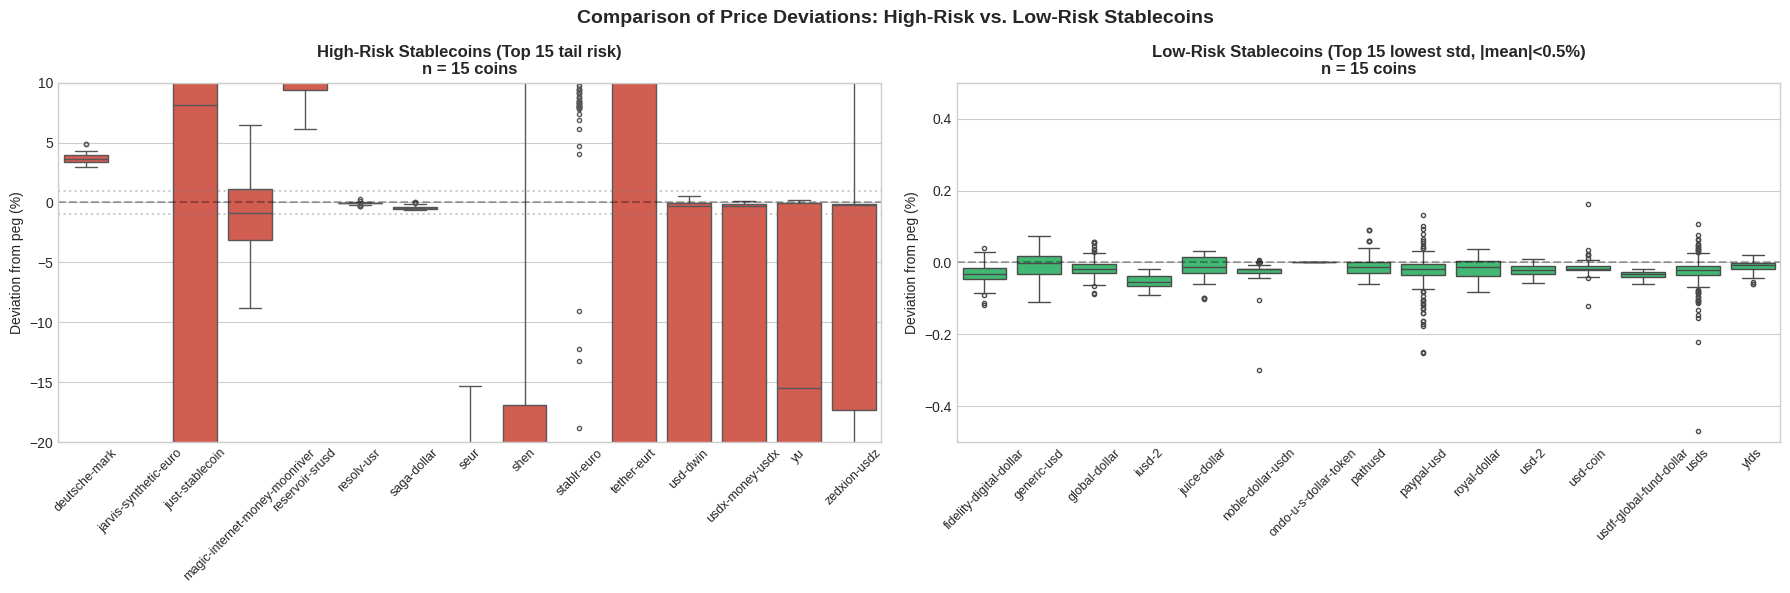

In [36]:
# ------------------------------------------------------------
# Improved selection: distinct high‑risk and low‑risk coins
# ------------------------------------------------------------
stats = df_all.groupby('coin')['deviation'].agg(['mean', 'std', 'min', 'max', 'count']).reset_index()

# 1. High‑risk: top 15 by tail_risk (as before)
stats['tail_risk'] = stats['std'] + np.maximum(-stats['min'], 0)
dangerous = stats.nlargest(15, 'tail_risk')['coin'].tolist()

# 2. Low‑risk: choose coins that are truly stable (|mean| < 0.5% and low std)
#    Exclude any coin that appears in dangerous (just in case)
stable_candidates = stats[(stats['mean'].abs() < 0.5) & (stats['std'] < 1.0)]
# If too few, relax criteria; if too many, take top 15 with lowest std
low_risk = stable_candidates.nsmallest(15, 'std')['coin'].tolist()
# Remove any overlap with dangerous
low_risk = [c for c in low_risk if c not in dangerous]

print(f"Low‑risk coins selected: {low_risk}")
print(f"High‑risk coins selected: {dangerous}")

# ------------------------------------------------------------
# Create a two‑panel figure
# ------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), sharey=False)
fig.patch.set_alpha(0)

# --- Panel 1: High‑risk coins ---
plot_df_high = df_all[df_all['coin'].isin(dangerous)]
sns.boxplot(data=plot_df_high, x='coin', y='deviation', ax=ax1, color='#e74c3c', fliersize=3)
ax1.set_title(f'High‑Risk Stablecoins (Top 15 tail risk)\nn = {len(dangerous)} coins', fontweight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Deviation from peg (%)')
ax1.tick_params(axis='x', rotation=45, labelsize=9)
ax1.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax1.axhline(y=1, color='gray', linestyle=':', alpha=0.4)
ax1.axhline(y=-1, color='gray', linestyle=':', alpha=0.4)
# Y‑limit: show full range, but cap at ±20% to avoid extreme outliers stretching the plot
ax1.set_ylim(-20, 10)
ax1.patch.set_alpha(0)

# --- Panel 2: Low‑risk coins ---
plot_df_low = df_all[df_all['coin'].isin(low_risk)]
sns.boxplot(data=plot_df_low, x='coin', y='deviation', ax=ax2, color='#2ecc71', fliersize=3)
ax2.set_title(f'Low‑Risk Stablecoins (Top 15 lowest std, |mean|<0.5%)\nn = {len(low_risk)} coins', fontweight='bold')
ax2.set_xlabel('')
ax2.set_ylabel('Deviation from peg (%)')
ax2.tick_params(axis='x', rotation=45, labelsize=9)
ax2.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax2.axhline(y=1, color='gray', linestyle=':', alpha=0.4)
ax2.axhline(y=-1, color='gray', linestyle=':', alpha=0.4)
# Zoom in to show the tiny deviations clearly
ax2.set_ylim(-0.5, 0.5)
ax2.patch.set_alpha(0)

plt.suptitle('Comparison of Price Deviations: High‑Risk vs. Low‑Risk Stablecoins', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/mnt/agents/output/stablecoin_risk_comparison_improved.png', dpi=300, bbox_inches='tight')
plt.show()


top volatile stalecoins: ['magic-internet-money-moonriver', 'rai', 'just-stablecoin']


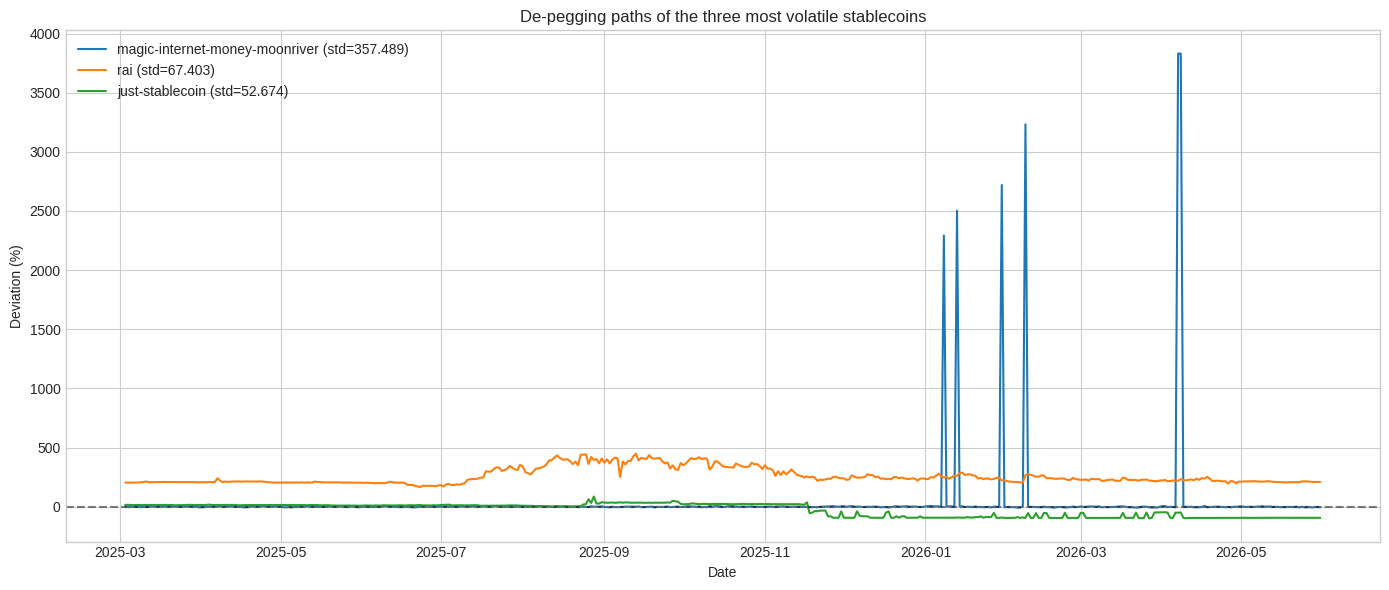

In [34]:
# 2: timeseries about highest volatile stablecoins
# sort deviation
vol_ranking = df_all.groupby('coin')['deviation'].std().sort_values(ascending=False)
top_vol_coins = vol_ranking.head(3).index.tolist()
print(f"\ntop volatile stalecoins: {top_vol_coins}")

fig = plt.figure(figsize=(14, 6))
fig.patch.set_alpha(0)
plt.gca().patch.set_alpha(0)

for coin in top_vol_coins:
    subset = df_all[df_all['coin'] == coin]
    plt.plot(subset['date'], subset['deviation'], label=f"{coin} (std={vol_ranking[coin]:.3f})")
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.axhline(y=1, color='gray', linestyle=':', alpha=0.5)  # % baseline
plt.axhline(y=-1, color='gray', linestyle=':', alpha=0.5)
plt.title('De-pegging paths of the three most volatile stablecoins') # depegging path
plt.xlabel('Date')
plt.ylabel('Deviation (%)')
plt.legend()
plt.tight_layout()
plt.show()

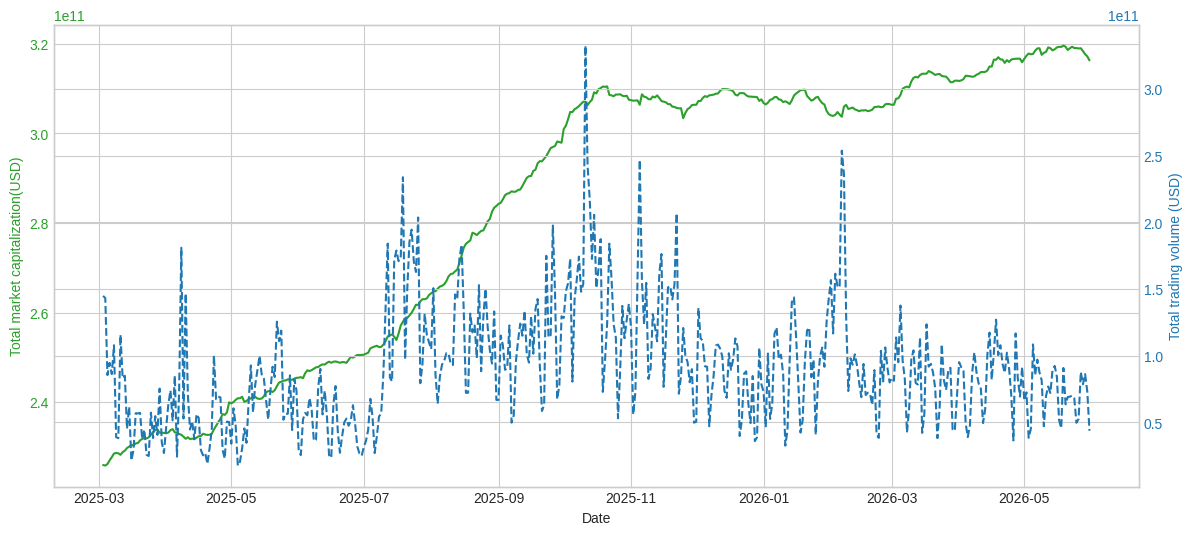

In [28]:
# 3 Total market capitalization(USD) and Total trading volume (USD)
# agg by day
daily_agg = df_all.groupby('date').agg({
    'market_caps': 'sum',
    'total_volumes': 'sum'
}).reset_index()

# plt
fig, ax1 = plt.subplots(figsize=(14, 6))
fig.patch.set_alpha(0)
color1 = 'tab:green'
ax1.set_xlabel('Date')
ax1.set_ylabel('Total market capitalization(USD)', color=color1)
ax1.plot(daily_agg['date'], daily_agg['market_caps'], color=color1, label='Total market capitalization')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.patch.set_alpha(0)

ax2 = ax1.twinx()
color2 = 'tab:blue'
ax2.set_ylabel('Total trading volume (USD)', color=color2)
ax2.plot(daily_agg['date'], daily_agg['total_volumes'], color=color2, linestyle='--', label='Total trading volume')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.patch.set_alpha(0)


In [14]:
# The largest negative deviation event (de-pegging and price collapse)
# negative spikes
neg_spikes = df_all.nsmallest(20, 'deviation')[['date', 'coin', 'deviation']]  # most neg top 10
print("\nThe largest negative deviation event (de-pegging and price collapse):")
print(neg_spikes)


The largest negative deviation event (de-pegging and price collapse):
             date      coin  deviation
103766 2026-02-06  usd-dwin     -100.0
103767 2026-02-07  usd-dwin     -100.0
103768 2026-02-08  usd-dwin     -100.0
103769 2026-02-09  usd-dwin     -100.0
103770 2026-02-10  usd-dwin     -100.0
103771 2026-02-11  usd-dwin     -100.0
103772 2026-02-12  usd-dwin     -100.0
103773 2026-02-13  usd-dwin     -100.0
103774 2026-02-14  usd-dwin     -100.0
103775 2026-02-15  usd-dwin     -100.0
103776 2026-02-16  usd-dwin     -100.0
103777 2026-02-17  usd-dwin     -100.0
103778 2026-02-18  usd-dwin     -100.0
103779 2026-02-19  usd-dwin     -100.0
103780 2026-02-20  usd-dwin     -100.0
103781 2026-02-21  usd-dwin     -100.0
103782 2026-02-22  usd-dwin     -100.0
103783 2026-02-23  usd-dwin     -100.0
103784 2026-02-24  usd-dwin     -100.0
103785 2026-02-25  usd-dwin     -100.0


total dead: 82

=== active stablecoisn but with strongest depegging top10===
        date                               coin  deviation
0 2026-03-28                               grai -48.175165
1 2025-06-29  novatti-australian-digital-dollar -46.073642
2 2026-03-28                      fathom-dollar -43.341216
3 2026-05-12                               nusd -42.101585
4 2025-03-13                       wemix-dollar -40.357116
5 2025-04-05                          forte-aud -39.652521
6 2025-05-12             celo-australian-dollar -36.258310
7 2025-12-02                           macropod -34.709462
8 2026-01-02                aussie-dollar-token -33.324000
9 2026-05-05                precious-metals-usd -31.222719


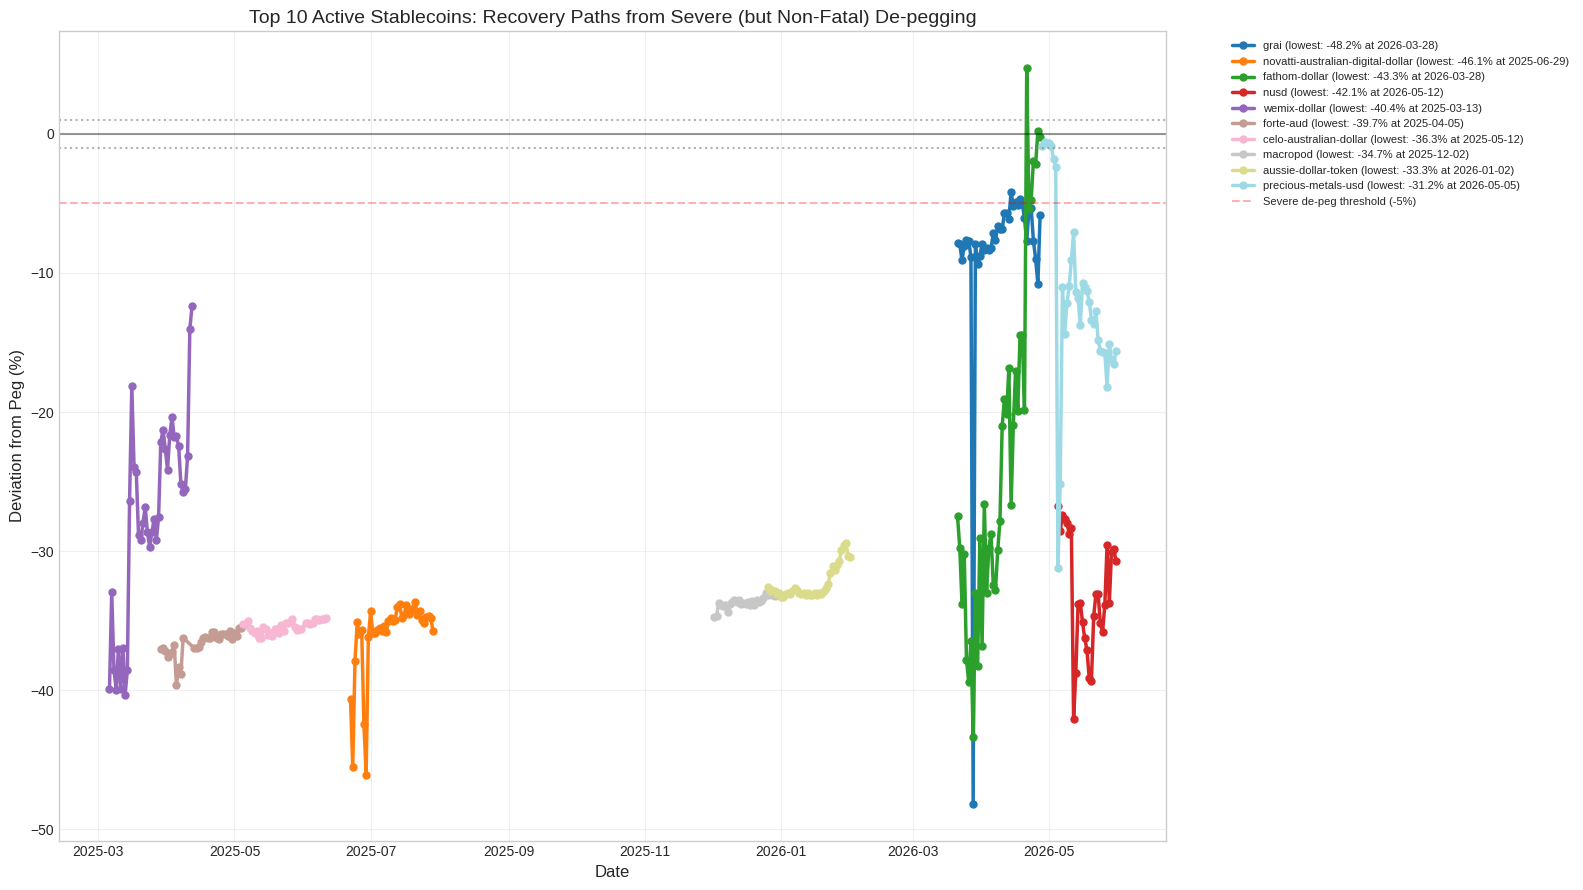


=== active stablecoins recovery days from severe deppeging===
                                coin  event_date  min_deviation  recovery_days
4                       wemix-dollar  2025-03-13     -40.357116          100.0
2                      fathom-dollar  2026-03-28     -43.341216           29.0
0                               grai  2026-03-28     -48.175165            NaN
1  novatti-australian-digital-dollar  2025-06-29     -46.073642            NaN
3                               nusd  2026-05-12     -42.101585            NaN
5                          forte-aud  2025-04-05     -39.652521            NaN
6             celo-australian-dollar  2025-05-12     -36.258310            NaN
7                           macropod  2025-12-02     -34.709462            NaN
8                aussie-dollar-token  2026-01-02     -33.324000            NaN
9                precious-metals-usd  2026-05-05     -31.222719            NaN


In [43]:


# filter after total dead

# 1. total dead: std in all time -50%（price < 0.5 USD）
coin_min_dev = df_all.groupby('coin')['deviation'].min().reset_index(name='min_dev')
dead_coins = coin_min_dev[coin_min_dev['min_dev'] < -50]['coin'].tolist()
print(f"total dead: {len(dead_coins)}")

# 2. alive
alive_df = df_all[~df_all['coin'].isin(dead_coins)]

# 3. alive coins: at lowerst:-1% 到 -50%
#   servere depegging
idx_min_alive = alive_df.groupby('coin')['deviation'].idxmin()
distinct_alive_events = alive_df.loc[idx_min_alive, ['date', 'coin', 'deviation']]
# std huge <-5%
distinct_alive_events = distinct_alive_events[distinct_alive_events['deviation'] < -5]
distinct_alive_events = distinct_alive_events.sort_values('deviation')

# 4. top 10
top_alive_spikes = distinct_alive_events.head(10).reset_index(drop=True)

print("\n=== active stablecoisn but with strongest depegging top10===")
print(top_alive_spikes)

# 5. path
fig = plt.figure(figsize=(16, 9))
fig.patch.set_alpha(0)
plt.gca().patch.set_alpha(0)

colors = plt.cm.tab20(np.linspace(0, 1, len(top_alive_spikes)))

for i, row in top_alive_spikes.iterrows():
    event_date = row['date']
    coin = row['coin']
    min_dev = row['deviation']

    subset = alive_df[
        (alive_df['coin'] == coin) &
        (alive_df['date'] >= event_date - pd.Timedelta(days=7)) &
        (alive_df['date'] <= event_date + pd.Timedelta(days=30))
    ].sort_values('date')

    if len(subset) > 1:
        plt.plot(
            subset['date'],
            subset['deviation'],
            marker='o',
            color=colors[i],
            linewidth=2.5,
            markersize=5,
            label=f"{coin} (lowest: {min_dev:.1f}% at {event_date.strftime('%Y-%m-%d')})"
        )

plt.axhline(y=0, color='black', linestyle='-', alpha=0.4)
plt.axhline(y=1, color='gray', linestyle=':', alpha=0.6)
plt.axhline(y=-1, color='gray', linestyle=':', alpha=0.6)
plt.axhline(y=-5, color='red', linestyle='--', alpha=0.3, label='Severe de-peg threshold (-5%)')

plt.title('Top 10 Active Stablecoins: Recovery Paths from Severe (but Non-Fatal) De-pegging', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Deviation from Peg (%)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. recovery back to ±1%
recovery_stats_alive = []
for i, row in top_alive_spikes.iterrows():
    coin = row['coin']
    event_date = row['date']
    sub = alive_df[(alive_df['coin'] == coin) & (alive_df['date'] >= event_date)].sort_values('date')
    if len(sub) < 2:
        continue
    recovered = sub[sub['deviation'].abs() <= 1]
    if len(recovered) > 0:
        days = (recovered.iloc[0]['date'] - event_date).days
    else:
        days = None
    recovery_stats_alive.append({
        'coin': coin,
        'event_date': event_date.strftime('%Y-%m-%d'),
        'min_deviation': row['deviation'],
        'recovery_days': days
    })

print("\n=== active stablecoins recovery days from severe deppeging===")
print(pd.DataFrame(recovery_stats_alive).sort_values('recovery_days', ascending=False))

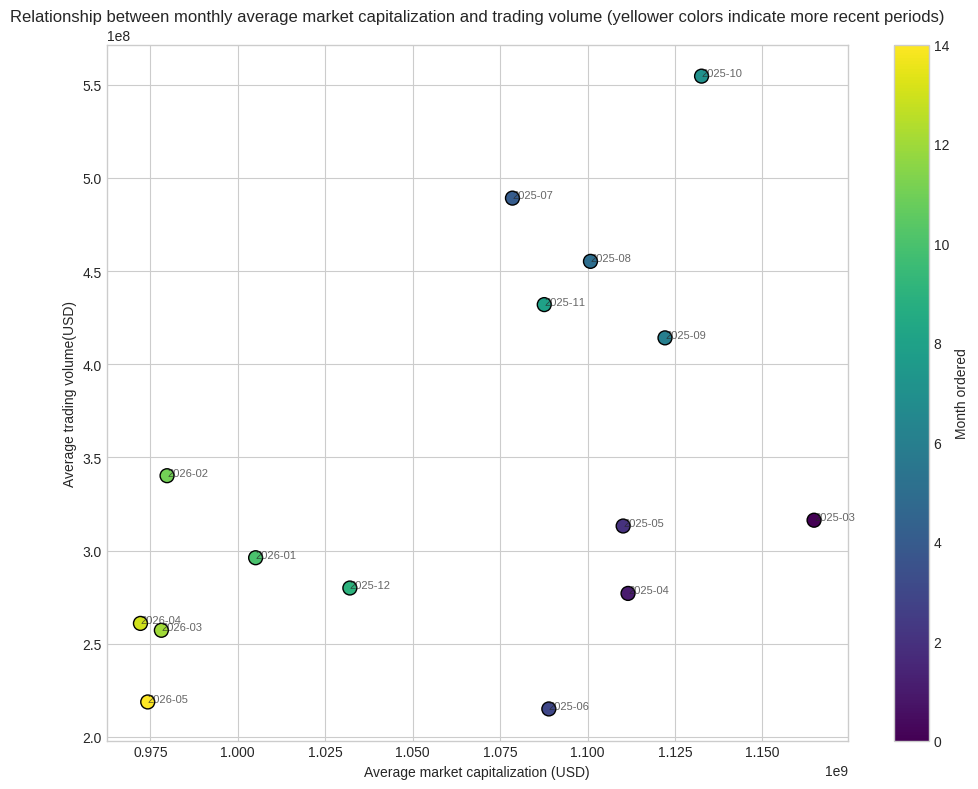

In [17]:
# ------------------- Average market capitalization vs Average trading volume(USD) -------------------
# sort by month av
df_all['month'] = df_all['date'].dt.to_period('M')
monthly_agg = df_all.groupby('month').agg({
    'market_caps': 'mean',
    'total_volumes': 'mean'
}).reset_index()
monthly_agg['month_str'] = monthly_agg['month'].astype(str)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(monthly_agg['market_caps'], monthly_agg['total_volumes'],
                      c=range(len(monthly_agg)), cmap='viridis', s=100, edgecolors='k')
plt.colorbar(scatter, label='Month ordered')
plt.xlabel('Average market capitalization (USD)')
plt.ylabel('Average trading volume(USD)')
plt.title('Relationship between monthly average market capitalization and trading volume (yellower colors indicate more recent periods)')#月度平均市值-交易量关系（颜色越黄表示越晚）
for i, row in monthly_agg.iterrows():
    plt.annotate(row['month_str'], (row['market_caps'], row['total_volumes']),
                 fontsize=8, alpha=0.7)
plt.tight_layout()
plt.show()


update: shock event, siginal and structual break

shock events：
  avg. change in 5 days: 1.01e+09, std: 1.65e+09
  threshold (±2σ): ±3.30e+09
  total shockevents: 33
  first shock: 2025-04-26
  last shock: 2026-03-07


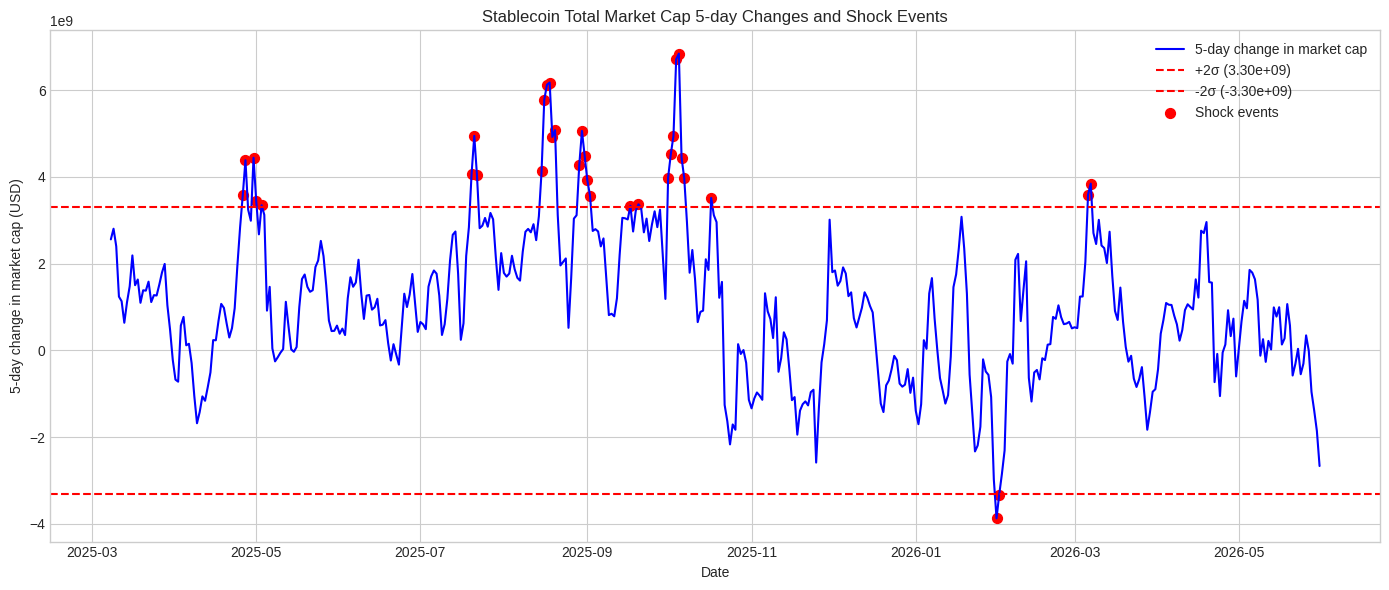

In [46]:


print("\n" + "="*60)
print("update: shock event, siginal and structual break")
print("="*60)


# daily marketcap and shockdates----------
daily_marketcap = df_all.groupby('date')['market_caps'].sum().reset_index().sort_values('date')
daily_marketcap['change_5d'] = daily_marketcap['market_caps'].diff(5)
mean_ch = daily_marketcap['change_5d'].mean()
std_ch = daily_marketcap['change_5d'].std()
threshold = 2 * std_ch
daily_marketcap['shock'] = np.abs(daily_marketcap['change_5d']) > threshold
shock_dates = daily_marketcap[daily_marketcap['shock']]['date'].tolist()

print(f"\nshock events：")
print(f"  avg. change in 5 days: {mean_ch:.2e}, std: {std_ch:.2e}")
print(f"  threshold (±2σ): ±{threshold:.2e}")
print(f"  total shockevents: {len(shock_dates)}")
if shock_dates:
    print(f"  first shock: {shock_dates[0].strftime('%Y-%m-%d')}")
    print(f"  last shock: {shock_dates[-1].strftime('%Y-%m-%d')}")

# save shock dates
#pd.DataFrame({'shock_date': shock_dates}).to_csv('/mnt/agents/output/shock_dates.csv', index=False)

# plz
fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_alpha(0)

ax.plot(daily_marketcap['date'], daily_marketcap['change_5d'], label='5-day change in market cap', color='blue')
ax.axhline(y=threshold, color='red', linestyle='--', label=f'+2σ ({threshold:.2e})')
ax.axhline(y=-threshold, color='red', linestyle='--', label=f'-2σ ({-threshold:.2e})')
shock_points = daily_marketcap[daily_marketcap['shock']]
ax.scatter(shock_points['date'], shock_points['change_5d'], color='red', s=50, label='Shock events')
ax.set_xlabel('Date')
ax.set_ylabel('5-day change in market cap (USD)')
ax.set_title('Stablecoin Total Market Cap 5-day Changes and Shock Events')
ax.legend()
ax.patch.set_alpha(0)
plt.tight_layout()
plt.savefig('/mnt/agents/output/shock_events.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
# ---------- De-pegging Frequency and Bank Run Signals ----------
#
print("\nextrem depegging coins（std>5 or abs mean >10, count > 50 ）：")
extreme = df_all.groupby('coin').agg({
    'deviation': ['mean', 'std', 'count']
}).reset_index()
extreme.columns = ['coin', 'mean', 'std', 'count']
extreme = extreme[extreme['count'] > 50]
extreme['extreme'] = (extreme['std'] > 5) | (np.abs(extreme['mean']) > 10)
print(extreme[extreme['extreme']].sort_values('std', ascending=False).head(10))


extrem depegging coins（std>5 or absolt avg >10, count > 50 ）：
                               coin        mean         std  count  extreme
177  magic-internet-money-moonriver   39.453053  357.489032    455     True
235                             rai  256.611158   67.402624    455     True
156                 just-stablecoin  -27.466712   52.674281    455     True
302                        usd-dwin  -49.097225   50.046621    273     True
285                     tether-eurt  -21.318325   48.622393    455     True
325                 usdx-money-usdx  -43.695017   48.296148    453     True
352                              yu  -35.816021   37.257937    356     True
357                    zedxion-usdz  -16.243723   35.269890    420     True
256                            shen  -42.226285   30.401383    455     True
240                      resolv-usr  -12.616801   29.764570    455     True


In [23]:
# Bank Run Signals（single-day drop of more than 5% and a surge in trading volume）
bank_run_list = []
for coin in df_all['coin'].unique():
    sub = df_all[df_all['coin'] == coin].sort_values('date').copy()
    if len(sub) < 20:
        continue
    sub['return'] = sub['prices'].pct_change() * 100
    # Rolling mean and standard deviation of trading volume
    vol_mean = sub['total_volumes'].rolling(20, min_periods=10).mean()
    vol_std = sub['total_volumes'].rolling(20, min_periods=10).std()
    sub['volume_spike'] = (sub['total_volumes'] > vol_mean + 2*vol_std) | (sub['total_volumes'] > vol_mean.shift(1) + 2*vol_std.shift(1))
    sub['bank_run'] = (sub['return'] < -5) & (sub['volume_spike'] == True)
    if sub['bank_run'].any():
        signals = sub[sub['bank_run']][['date', 'prices', 'total_volumes', 'deviation', 'return']]
        signals['coin'] = coin
        bank_run_list.append(signals)

if bank_run_list:
    all_bankruns = pd.concat(bank_run_list)
    print(f"\nfind  {len(all_bankruns)} bankrun signals")
    print(all_bankruns.head(10))
    all_bankruns.to_csv('/mnt/agents/output/bank_run_signals.csv', index=False)
else:
    print("\nNo run signal detected (threshold may be too strict).")


find  258 bankrun signals
           date    prices  total_volumes   deviation     return         coin
59   2025-08-15  0.010719   6.380772e+06  -98.928061 -13.781470         a7a5
113  2025-10-08  0.011488   8.714054e+03  -98.851239  -5.321128         a7a5
4049 2025-12-26  0.886793   1.216387e+05  -11.320690 -10.374165   anzen-usdz
4295 2025-10-11  0.930703   7.578580e+05   -6.929736  -6.645191  anzens-usda
5072 2025-09-09  1.163795   2.929293e+02   16.379539 -18.383489   aryze-eeur
5093 2025-09-30  1.167384   7.529488e+01   16.738420  -9.537296   aryze-eeur
5134 2025-11-12  1.007170   3.872036e+02    0.716974 -13.136554   aryze-eeur
5496 2025-09-12  2.036767   1.189154e+03  103.676673 -26.720408   aryze-egbp
5515 2025-10-01  1.344169   2.210354e+03   34.416906 -32.938121   aryze-egbp
5711 2026-05-04  1.114380   1.285894e+02   11.437957 -17.420578   aryze-egbp


In [24]:
# Show the recovery path of the largest derailment event
# Calculate recovery time: the number of days required to return from the lowest deviation point to a deviation absolute value of <1%.
recovery_times = []
for coin in df_all['coin'].unique():
    sub = df_all[df_all['coin'] == coin].sort_values('date')
    if len(sub) < 20:
        continue
    # max neg dev.
    min_idx = sub['deviation'].idxmin()
    min_date = sub.loc[min_idx, 'date']
    # after min date find next |deviation| <= 1%
    sub_after = sub[sub['date'] >= min_date]
    recovery_idx = sub_after[sub_after['deviation'].abs() <= 1].index
    if len(recovery_idx) > 0:
        recovery_date = sub_after.loc[recovery_idx[0], 'date']
        days = (recovery_date - min_date).days
        recovery_times.append({'coin': coin, 'min_deviation': sub.loc[min_idx, 'deviation'],
                               'recovery_days': days, 'event_date': min_date})
recovery_df = pd.DataFrame(recovery_times)
print("\nRecovery time statistics for extreme anchor break-off events (top 10)：")
print(recovery_df.sort_values('recovery_days', ascending=False).head(10))
recovery_df.to_csv('/mnt/agents/output/recovery_times.csv', index=False)


Recovery time statistics for extreme anchor break-off events (top 10)：
                              coin  min_deviation  recovery_days event_date
9                       aryze-eeur      -1.309755            252 2025-03-05
220                    zasset-zusd     -61.198245            224 2025-06-28
91                     kolibri-usd     -14.894241            146 2025-03-10
216                    youves-uusd     -17.106160            145 2025-03-21
209                   wemix-dollar     -40.357116            100 2025-03-13
199                         usdtez     -28.507023             97 2025-04-15
221  zephyr-protocol-stable-dollar     -28.146868             61 2025-04-11
21                         bookusd      -5.761539             60 2025-06-24
37                     defi-dollar      -6.854641             53 2026-02-13
134                     pareto-usp     -99.990400             44 2025-07-14


In [25]:
# ---------- Structural breakpoints in trading volume ----------
!pip install ruptures -q
import ruptures as rpt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.6 MB/s eta 0:00:00


In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import os
import glob
from datetime import datetime


Structural breakpoints in trading volume (pen=10):
  2025-07-11
  2025-11-23


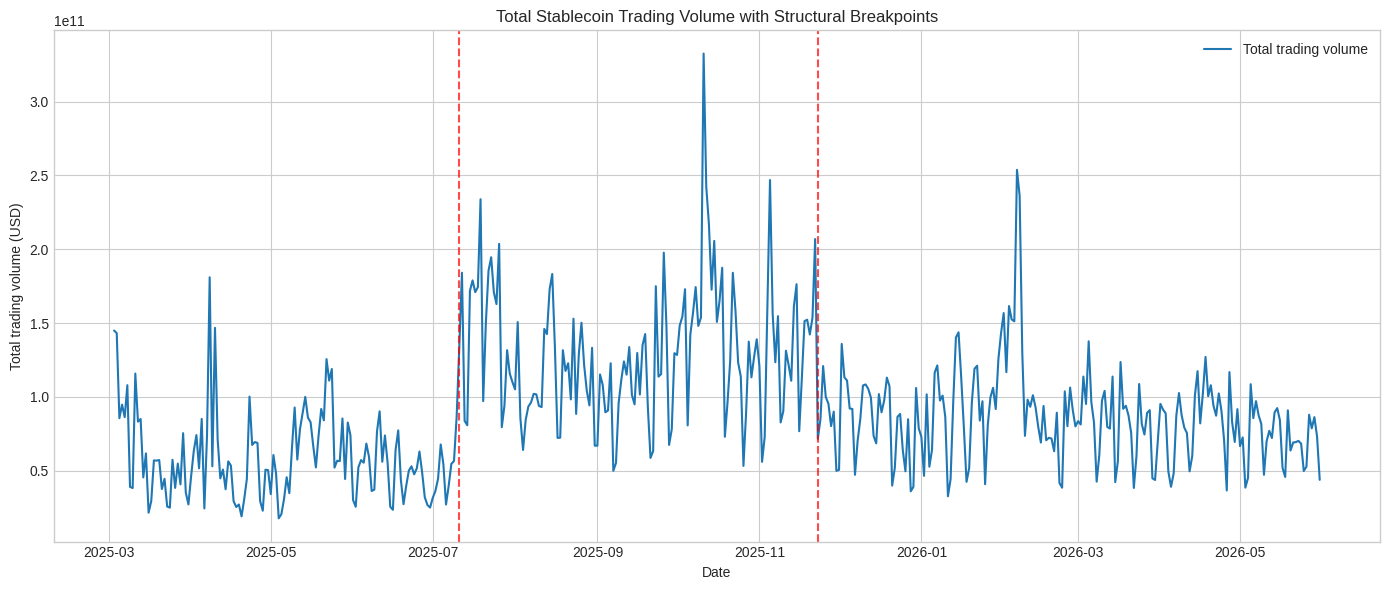

In [50]:
daily_volume = df_all.groupby('date')['total_volumes'].sum().reset_index().sort_values('date')
signal = daily_volume['total_volumes'].values.reshape(-1, 1)
algo = rpt.Pelt(model="rbf").fit(signal)
breakpoints = algo.predict(pen=10)  # pen to control stuctual break points
break_dates = [daily_volume['date'].iloc[bp] for bp in breakpoints[:-1]]

print(f"\nStructural breakpoints in trading volume (pen=10):")
for d in break_dates:
    print(f"  {d.strftime('%Y-%m-%d')}")

# plz
fig = plt.figure(figsize=(14, 6))
fig.patch.set_alpha(0)
plt.gca().patch.set_alpha(0)
plt.plot(daily_volume['date'], daily_volume['total_volumes'], label='Total trading volume')
for d in break_dates:
    plt.axvline(d, color='red', linestyle='--', alpha=0.7)
plt.xlabel('Date')
plt.ylabel('Total trading volume (USD)')
plt.title('Total Stablecoin Trading Volume with Structural Breakpoints')
plt.legend()
plt.tight_layout()
plt.savefig('/mnt/agents/output/volume_breakpoints.png', dpi=300, bbox_inches='tight')
plt.show()

In [27]:

print("\navg volumn in each periods：")
for i, bp in enumerate(break_dates):
    if i == 0:
        start = daily_volume['date'].min()
    else:
        start = break_dates[i-1] + pd.Timedelta(days=1)
    end = bp
    seg = daily_volume[(daily_volume['date'] >= start) & (daily_volume['date'] <= end)]
    avg = seg['total_volumes'].mean()
    print(f"  {start.strftime('%Y-%m-%d')} ~ {end.strftime('%Y-%m-%d')}: {avg:.2e}")
last_start = break_dates[-1] + pd.Timedelta(days=1)
last_seg = daily_volume[daily_volume['date'] >= last_start]
if len(last_seg) > 0:
    avg = last_seg['total_volumes'].mean()
    print(f"  {last_start.strftime('%Y-%m-%d')} ~ {daily_volume['date'].max().strftime('%Y-%m-%d')}: {avg:.2e}")




avg volumn in each periods：
  2025-03-03 ~ 2025-07-11: 5.94e+10
  2025-07-12 ~ 2025-11-23: 1.29e+11
  2025-11-24 ~ 2026-05-31: 8.61e+10
